# Ćwiczenie 0: Wprowadzenie do JupyterLab i PYNQ na platformie RFSoC

**Czas:** 200 min  |  **Platforma:** RFSoC + PYNQ  |  **Overlay:** `rfsoc_qpsk` (Strathclyde SDR)

| Blok | Czas | Temat |
|---|---|---|
| 1 | 15 min | Połączenie, JupyterLab, instalacja pakietu |
| 2 | 25 min | Python / NumPy / FFT |
| 3 | 20 min | Architektura PYNQ i overlayu `rfsoc_qpsk` |
| 4 | 25 min | Overlay, hierarchia IP, rejestry MMIO |
| – | 10 min | Przerwa |
| 5 | 30 min | Przechwytywanie danych przez DMA |
| 6 | 25 min | Pomiar czasu transferu DMA |
| 7 | 40 min | Mini-projekt: analiza toru QPSK |
| 8 | 10 min | Podsumowanie |

**Imię i nazwisko / grupa:** ....Kristina Pavlovska....

Komórki oznaczone **ZADANIE** wymagają uzupełnienia kodu (`# TODO`) lub odpowiedzi własnymi słowami.

## Blok 1. Połączenie, JupyterLab i instalacja pakietu (15 min)

1. Otwórz w przeglądarce adres płytki podany przez prowadzącego (zwykle `http://<IP>:9090`).
2. Zapoznaj się z interfejsem: przeglądarka plików, Launcher, terminal, notebooki.
3. Uruchom komórkę poniżej (to samo możesz wykonać w **Terminalu**).
4. Zainstaluj pakiet `rfsoc_qpsk` z przykładowym overlayem. W **Terminalu** (płytka musi mieć dostęp do internetu) wykonaj polecenie `pip3 install ...` podane w README repozytorium <https://github.com/strath-sdr/rfsoc_qpsk>, a następnie `python3 -m rfsoc_qpsk install`. Drugie polecenie instaluje notebooki demonstracyjne w przestrzeni roboczej.

In [1]:
import os, importlib.util

!uname -m
!python3 --version
!nproc
print("BOARD =", os.environ.get("BOARD"))
print("pakiet rfsoc_qpsk zainstalowany:", importlib.util.find_spec("rfsoc_qpsk") is not None)

arm64
Python 3.14.8
zsh:1: command not found: nproc
BOARD = None
pakiet rfsoc_qpsk zainstalowany: False


**ZADANIE 1.1** Uzupełnij na podstawie wyników powyżej:



- Architektura procesora: `...`
- Płytka (`BOARD`): `...`
- Liczba rdzeni: `...`
- Czy pakiet `rfsoc_qpsk` jest zainstalowany?: `...`

## Blok 2. Python, NumPy i FFT (25 min)

Zanim użyjemy sprzętu, przypomnijmy podstawy analizy widmowej, które wykorzystamy w kolejnych ćwiczeniach.

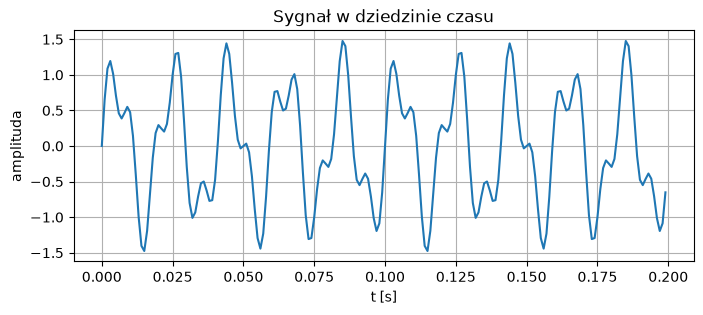

In [2]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

fs = 1000                    # częstotliwość próbkowania [Hz]
t = np.arange(0, 1, 1/fs)    # 1 s sygnału
x = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)

plt.figure(figsize=(8, 3))
plt.plot(t[:200], x[:200])
plt.xlabel("t [s]"); plt.ylabel("amplituda"); plt.grid(True)
plt.title("Sygnał w dziedzinie czasu")
plt.show()

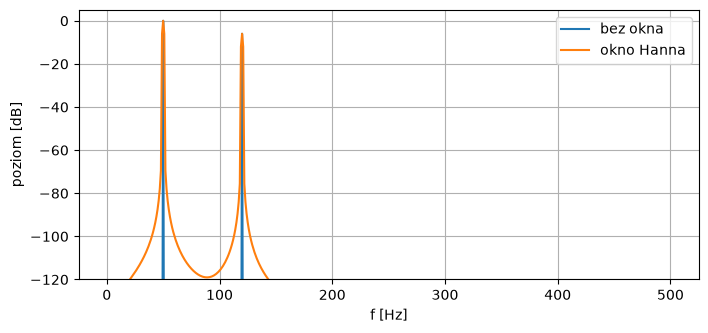

In [3]:
def widmo_db(x, fs, okno=None):
    """Zwraca (f, |X| w dB) dla sygnału rzeczywistego."""
    N = len(x)
    w = np.ones(N) if okno is None else okno(N)
    X = np.fft.rfft(x * w)
    # normalizacja przez sumę okna, by amplituda sinusoidy była porównywalna
    X = np.abs(X) / (np.sum(w) / 2)
    f = np.fft.rfftfreq(N, 1/fs)
    return f, 20*np.log10(X + 1e-12)

f1, X1 = widmo_db(x, fs)
f2, X2 = widmo_db(x, fs, np.hanning)

plt.figure(figsize=(8, 3.5))
plt.plot(f1, X1, label="bez okna")
plt.plot(f2, X2, label="okno Hanna")
plt.xlabel("f [Hz]"); plt.ylabel("poziom [dB]")
plt.ylim(-120, 5); plt.grid(True); plt.legend()
plt.show()

**ZADANIE 2.1** Zmień częstotliwość pierwszego tonu na **50,5 Hz** (nie jest to wielokrotność rozdzielczości FFT) i porównaj widma z oknem i bez okna.
Opisz, co widzisz i dlaczego (zjawisko przecieku widmowego).

**Odpowiedź:** ...

In [4]:
# ZADANIE 2.1: TODO – wygeneruj sygnał z tonem 50.5 Hz i porównaj widma
# x2 = ...
# f_a, X_a = widmo_db(x2, fs)
# f_b, X_b = widmo_db(x2, fs, np.hanning)
# ... wykres ...

**ZADANIE 2.2** Dodaj do sygnału szum gaussowski i znajdź taki poziom szumu, przy którym ton 120 Hz o amplitudzie 0,5 przestaje być widoczny w widmie.
Zapisz wartość odchylenia standardowego szumu.

In [5]:
# ZADANIE 2.2: TODO
# sigma = ...
# x_n = x + sigma*np.random.randn(len(x))

## Blok 3. Architektura PYNQ i overlayu `rfsoc_qpsk` (20 min)

**PYNQ** pozwala sterować logiką programowalną (PL) z Pythona działającego na procesorze (PS) pod Linuksem.

- **PS:** rdzenie ARM, Linux, JupyterLab, Python.
- **PL:** logika FPGA — bloki DSP, DMA i tor RF (ADC/DAC).
- **Overlay** = bitstream `.bit` + opis sprzętu `.hwh` + opcjonalny moduł `.py` ze sterownikami.
- **PS ⇄ PL:** rejestry przez **AXI-Lite / MMIO** (sterowanie) oraz dane przez **AXI-Stream + DMA**.

**Overlay `rfsoc_qpsk`** to kompletny transceiver QPSK zrealizowany w PL:

- hierarchia `qpsk_tx`: generator symboli QPSK i filtr kształtujący,
- hierarchia `qpsk_rx`: odbiornik z etapami decymacji (`dec`), synchronizacji zgrubnej (`csync`), filtru dopasowanego RRC (`rrc`) i synchronizacji symboli (`tsync`),
- blok `usp_rf_data_converter_0`: przetworniki DAC i ADC,
- **bloki DMA w trybie przechwytywania** (kierunek PL → PS): `dma_tx_fft`, `dma_tx_time`, `dma_tx_symbol`, `dma_rx_dec`, `dma_rx_csync`, `dma_rx_rrc`, `dma_rx_tsync`. Każdy kopiuje do pamięci PS jedną, krótką ramkę z wybranego punktu toru.

Strumień próbek zostaje więc w PL, a Python pobiera z niego „zdjęcia” do analizy i wizualizacji.

**ZADANIE 3.1** Narysuj schemat toru: generator QPSK → DAC → (pętla) → ADC → odbiornik. Zaznacz punkty, w których DMA pobiera próbki, oraz które połączenia to AXI-Lite, a które AXI-Stream.



**Schemat / opis:** ...

## Blok 4. Overlay, hierarchia IP i rejestry MMIO (25 min)

Załaduj overlay. Klasa `QpskOverlay` dziedziczy po `pynq.Overlay`: wczytuje bitstream, konfiguruje zegary i przetworniki RF oraz udostępnia hierarchie `qpsk_tx` i `qpsk_rx`.

In [7]:
import os
from pynq import allocate
from rfsoc_qpsk.qpsk_overlay import QpskOverlay

print("Płytka:", os.environ.get("BOARD"))
ol = QpskOverlay()          # trwa kilka sekund: konfiguruje zegary i przetworniki RF
print("Overlay załadowany.")

ModuleNotFoundError: No module named 'pynq'

In [9]:
# Lista bloków IP pogrupowana według hierarchii
from collections import defaultdict

grupy = defaultdict(list)
for nazwa, opis in ol.ip_dict.items():
    grupa = nazwa.split("/")[0] if "/" in nazwa else "(poziom główny)"
    grupy[grupa].append((nazwa, opis["type"]))

for grupa, lista in grupy.items():
    print(f"\n== {grupa} ==")
    for nazwa, typ in lista:
        print(f"  {nazwa:32s} {typ}")

NameError: name 'ol' is not defined

**ZADANIE 4.1** Z listy powyżej wskaż:



- bloki DMA: `...`
- bloki z rejestrami sterującymi (rdzenie QPSK): `...`
- blok przetworników RF: `...`

In [10]:
# Adresy bazowe i zakresy rejestrów
for nazwa, opis in ol.ip_dict.items():
    if 'phys_addr' in opis and 'addr_range' in opis:
        print(f"{nazwa:32s} adres: {hex(opis['phys_addr'])}  zakres: {hex(opis['addr_range'])}")
    else:
        print(f"{nazwa:32s}")

NameError: name 'ol' is not defined

**Rejestry przez MMIO.** Rdzeń nadajnika ma rejestry 32-bitowe dostępne przez `mmio`. Sterownik udostępnia metodę `set_gain()`, która zapisuje wzmocnienie wyjściowe do jednego z nich. Zobacz jej kod i sprawdź, co faktycznie trafia do rejestru.

**Uwaga:** nie zapisuj do innych rejestrów niż wskazane przez prowadzącego.

In [11]:
import inspect
import rfsoc_qpsk.qpsk_tx as mod_tx

print(inspect.getsource(mod_tx.QPSKTx.set_gain))

ModuleNotFoundError: No module named 'rfsoc_qpsk'

In [12]:
tx = ol.qpsk_tx                 # hierarchia nadajnika (sterownik QPSKTx)
rdzen = tx.qpsk_tx              # rdzeń z rejestrami AXI-Lite
print("adres bazowy rdzenia:", hex(rdzen.mmio.base_addr))

for g in (0.0, 0.25, 0.5, 1.0):
    tx.set_gain(g)
    print(f"gain = {g:4.2f}  ->  rejestr[44] = {int(rdzen.mmio.array[44 >> 2]):#010x}")
tx.set_gain(1.0)

NameError: name 'ol' is not defined

**ZADANIE 4.2** Na podstawie kodu `set_gain()` i odczytów zapisz wzór, według którego wartość znormalizowana trafia do rejestru, i porównaj go z wynikami. Wyjaśnij, dlaczego `gain = 1,0` nie daje pełnej skali rejestru.



**Odpowiedź:** ...

---
### ☕ Przerwa (10 min)
---

## Blok 5. Przechwytywanie danych przez DMA (30 min)

DMA w tym overlayu działa w jedną stronę (PL → PS). Rdzeń po ustawieniu rejestru `transfer_*` wysyła jedną ramkę próbek strumieniem AXI-Stream, a DMA zapisuje ją do bufora w pamięci PS. Bufor tworzy się przez `pynq.allocate` (pamięć fizycznie ciągła, adresowalna przez DMA). Sterownik robi to za nas w metodach `get_*`. Najpierw ich użyjemy, a potem odtworzymy jedną z nich ręcznie.

In [13]:
tx, rx = ol.qpsk_tx, ol.qpsk_rx

sym  = tx.get_many_symbols(20)      # 20 ramek po 16 symboli (dma_tx_symbol)
czas = tx.get_shaped_time()         # 128 próbek zespolonych po filtrze kształtującym (dma_tx_time)
print("symbole:", sym.shape, sym.dtype, "| próbki w czasie:", czas.shape, czas.dtype)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(sym.real, sym.imag, "o", alpha=0.4)
ax[0].set_title("Symbole nadajnika"); ax[0].set_xlabel("I"); ax[0].set_ylabel("Q")
ax[0].set_aspect("equal"); ax[0].grid(True)
ax[1].plot(czas.real, label="I"); ax[1].plot(czas.imag, label="Q")
ax[1].set_title("Sygnał po filtrze kształtującym"); ax[1].set_xlabel("numer próbki")
ax[1].grid(True); ax[1].legend()
plt.tight_layout(); plt.show()
print("unikalne symbole:", np.unique(sym))

NameError: name 'ol' is not defined

**ZADANIE 5.1** Ile różnych punktów ma konstelacja symboli nadajnika i jakie mają wartości? Dlaczego symbole wyglądają idealnie, a sygnał po filtrze kształtującym zupełnie inaczej?



**Odpowiedź:** ...

### Ręczny transfer DMA

Poniższy kod robi dokładnie to, co `tx.get_shaped_time()`: ustawia rejestr `transfer_time`, uruchamia odbiór w DMA, czeka na koniec i zwalnia rejestr. Kolejność jest istotna.

> **Nie wywołuj `wait()` bez wcześniejszego ustawienia `transfer_time = 1`.** Rdzeń nie wyśle danych, więc `wait()` się nie zakończy i trzeba będzie zrestartować kernel.

In [14]:
buf   = allocate(shape=(256,), dtype=np.int16)   # 128 próbek I/Q w przeplocie: I, Q, I, Q, ...
rdzen = ol.qpsk_tx.qpsk_tx                       # rdzeń nadajnika (rejestry AXI-Lite)
dma   = ol.qpsk_tx.dma_tx_time                   # DMA przechwytujące sygnał w dziedzinie czasu

rdzen.transfer_time = 1                          # 1) rdzeń zaczyna wysyłać ramkę
dma.recvchannel.transfer(buf)                    # 2) DMA zapisuje ją do bufora
dma.recvchannel.wait()                           # 3) czekamy na koniec transferu
rdzen.transfer_time = 0                          # 4) kończymy przechwytywanie

raw = np.array(buf)                              # kopia danych z bufora
print("surowe dane (int16):", raw[:8])

# TODO: zbuduj z `raw` wektor zespolony (I = próbki parzyste, Q = nieparzyste),
#       narysuj część rzeczywistą i urojoną, porównaj kształt i zakres wartości z tx.get_shaped_time()

buf.freebuffer()

NameError: name 'allocate' is not defined

**ZADANIE 5.2** Porównaj wynik ręcznego transferu z `get_shaped_time()`. Czy ramki są identyczne? Czy mają ten sam format i zakres wartości? Co by się stało, gdybyś pominął ustawienie `transfer_time = 1`?



**Odpowiedź:** ...

## Blok 6. Pomiar czasu transferu DMA (25 min)

Zmierz czas pobrania jednej ramki z różnych punktów toru. Rozmiary ramek wynikają z rozmiarów buforów w sterowniku. Pomiar obejmuje też krótką obróbkę w Pythonie (zamiana na liczby zespolone), więc to czas „od wywołania metody do gotowej tablicy”.

In [15]:
import time

zrodla = {
    "tx_symbol (16 B)":  (tx.get_symbols,      16),
    "rx_tsync (64 B)":   (rx.get_data,         64),
    "tx_time (512 B)":   (tx.get_shaped_time,  512),
    "rx_dec (512 B)":    (rx.get_decimated,    512),
    "rx_rrc (2048 B)":   (rx.get_rrced,        2048),
    "tx_fft (4096 B)":   (tx.get_shaped_fft,   4096),
}

POWTORZENIA = 100
wyniki = {}                       # nazwa -> mediana czasu jednej ramki [s]
for nazwa, (funkcja, bajty) in zrodla.items():
    funkcja()                     # rozgrzewka
    czasy = []
    for _ in range(POWTORZENIA):
        t0 = time.perf_counter()
        funkcja()
        czasy.append(time.perf_counter() - t0)
    wyniki[nazwa] = np.median(czasy)
    print(f"{nazwa:18s} czas = {wyniki[nazwa]*1e6:8.0f} µs   przepustowość = {bajty/wyniki[nazwa]/1e6:7.2f} MB/s")

NameError: name 'tx' is not defined

In [16]:
bajty = np.array([b for _, b in zrodla.values()], float)
t_med = np.array([wyniki[n] for n in zrodla], float)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].semilogx(bajty, t_med*1e6, "o-")
ax[0].set_xlabel("rozmiar ramki [B]"); ax[0].set_ylabel("czas [µs]")
ax[1].semilogx(bajty, bajty/t_med/1e6, "o-")
ax[1].set_xlabel("rozmiar ramki [B]"); ax[1].set_ylabel("przepustowość [MB/s]")
for a in ax:
    a.grid(True, which="both")
plt.tight_layout(); plt.show()

NameError: name 'zrodla' is not defined

In [17]:
# TODO: dopasuj prostą  czas = a·bajty + b  (np.polyfit) i wypisz narzut stały b [µs] oraz czas na bajt a [ns/B]

Znajdź w kodzie overlayu, z jaką częstotliwością próbkowania pracują przetworniki, i porównaj szybkość przechwytywania z szybkością strumienia w torze RF.

In [18]:
import inspect
import rfsoc_qpsk.qpsk_overlay as mod_ol

for linia in inspect.getsource(mod_ol).splitlines():
    if "DynamicPLLConfig" in linia:
        print(linia.strip())

ModuleNotFoundError: No module named 'rfsoc_qpsk'

In [19]:
# TODO: na podstawie wydruku podaj fs_rf [Sa/s], policz szybkość strumienia RF (2 B na próbkę ADC),
#       szybkość przechwytywania dla ramki tx_time (512 B) i ich stosunek
fs_rf = None

**ZADANIE 6.1** Wyjaśnij kształt wykresów i wyniki dopasowania. Od czego zależy czas pobrania ramki? Czy tym torem da się zapisać ciągły strumień z ADC? Odpowiedź uzasadnij liczbami.



**Odpowiedź:** ...

## Blok 7. Mini-projekt: analiza toru QPSK (40 min)

**Cel:** zbadać odbiornik QPSK, pobierając ramki z kolejnych etapów toru (`dec` → `csync` → `rrc` → `tsync`), oraz widmo sygnału nadajnika.

**Wymagania:**
1. Zbierz po 100 ramek z czterech punktów odbiornika i narysuj cztery konstelacje obok siebie.
2. Oblicz **EVM** [%] dla symboli po synchronizacji (`tsync`). Konstelacja może być obrócona względem osi, więc najpierw oszacuj jej orientację (wskazówka: faza średniej z `s⁴`).
3. Wyznacz widmo sygnału nadajnika: uśrednij periodogramy z 50 ramek `get_shaped_time()` (okno Hanna) i oszacuj szerokość pasma −20 dB.
4. Opisz wnioski: jak zmienia się konstelacja po kolejnych etapach i jak EVM zależy od `tx.set_gain()`.

**Warunek:** DAC musi być połączony z ADC (pętla RF) — zapytaj prowadzącego.

In [20]:
N_RAMEK = 100
dane = {
    "dec":   np.concatenate([rx.get_decimated()     for _ in range(N_RAMEK)]),
    "csync": np.concatenate([rx.get_coarse_synced() for _ in range(N_RAMEK)]),
    "rrc":   np.concatenate([rx.get_rrced()         for _ in range(N_RAMEK)]),
    "tsync": np.concatenate([rx.get_data()          for _ in range(N_RAMEK)]),
}
for nazwa, v in dane.items():
    print(f"{nazwa:6s} {len(v):6d} próbek, typ {v.dtype}")

NameError: name 'rx' is not defined

In [21]:
# TODO 1: cztery konstelacje (Re vs Im) w jednym rzędzie, równe skale osi, siatka

In [22]:
# TODO 2: funkcja ewm(s) -> EVM [%] i wynik dla dane["tsync"]
def ewm(s):
    ...

# print(f"EVM (tsync) = {ewm(dane['tsync']):.1f} %")

In [23]:
# TODO 3: widmo nadajnika – uśrednione periodogramy 50 ramek (okno Hanna), oś w cyklach/próbkę,
#         szerokość pasma -20 dB

**Wnioski z mini-projektu:**

...

## Blok 8. Podsumowanie i pytania kontrolne (10 min)

1. Czym różni się PS od PL i do czego służy każda z części?
2. Co zawiera overlay i do czego potrzebny jest plik `.hwh`?
3. Dlaczego w PYNQ używa się `allocate` zamiast zwykłych tablic NumPy?
4. Kiedy stosuje się MMIO (AXI-Lite), a kiedy DMA (AXI-Stream)? Dlaczego DMA w overlayu `rfsoc_qpsk` działa tylko w kierunku PL → PS?
5. Dlaczego czas pobrania ramki prawie nie zależy od jej rozmiaru?
6. Jakie informacje o torze QPSK dały Ci konstelacje i EVM?

**Odpowiedzi:**

1. ...
2. ...
3. ...
4. ...
5. ...
6. ...

---
**Przed zakończeniem:** zapisz notebook (`Ctrl+S`), pobierz go na swój komputer (prawy przycisk → *Download*) i wyłącz kernel (*Kernel → Shut Down All Kernels*).